# Multiarrange analysis

This notebook analyzes the participant responses from the experiment and produces figures and tables for the paper.
It uses outputs from `notebooks/multiarrange_analysis.py` as part of the analysis.

## Preliminaries

First, we import some useful libraries.
The `analysis_functions` import handles some utilities I wrote that would clutter up the notebook; for example, functions processing Meadows-formatted multiarrange data, whose native JSON format is not particularly helpful.
Change `SAVE_FIGURE_MODE` to `True` if the figure and table outputs are to be saved.

In [1]:
# Imports
from fileorganize import dir_to_df
import re
import json
import sys
import numpy as np
from scipy.spatial.distance import squareform
from matplotlib.pyplot import matshow, show
import matplotlib.pyplot as plt
from pathlib import Path
from itertools import combinations, product
import pandas as pd
from sklearn.manifold import MDS
import random 
import pypst
import statsmodels.api as sm

sys.path.append(str(Path.cwd().parent / "src")) # Import the custom functions
from analysis_functions import *

from cycler import cycler
plt.rcParams['axes.prop_cycle'] = cycler(color=['#002676', '#FDB515', '#00553A', '#770747', '#431170'])

SEED = 84
random.seed(SEED)

In [2]:
# Project directory
project_dir = Path.cwd().parent

# Directories we'll be saving things to
FIGURE_DIR = project_dir / 'figures/'
RESULTS_DIR = project_dir / 'data/results/'

# Files we'll be reading from
FRICATIVE_RELPATH = '../data/processed/fricative_df.pkl'
DATA_RELPATH = '../data/raw'

# Some constants
MEADOWS_FILE_FORMAT = r'Meadows_Pilot-fricative-multiarrange_v_v(\d)_(annotations|metadata|tree)\.(csv|json)'

# Save figures?
SAVE_FIGURE_MODE = False

## Fricative statistics table

Next, we import the dataframe of fricative descriptive statistics.
The file was generated by `notebooks/fricative_stimuli_analysis.py` from the stimuli used in the experiment.
We won't use it again until later in the notebook.

In [3]:
fricative_df = pd.read_pickle(FRICATIVE_RELPATH).reset_index(drop=True)
fric_symbols = {label: val for idx, label, val in fricative_df[['fricative_label', 'fricative']].itertuples()}
fricative_df

,fricative_label,Fm,Am,AmpD,Fsec,Asec,COG,SD,Skew,Kurtosis,...,DCT1,DCT2,DCT3,textgrid_name,fricative,fricative_dur,syllable,syllable_dur,vowel,vowel_dur
0,bilabial,2600.0,-34.506097,11.239639,3675.0,-36.172456,4064.207102,2508.411885,0.523847,-0.434943,...,5805.578985,-346.876808,443.378313,Voiceless_bilabial_fricative.TextGrid,ɸ,0.264700,ɸa,0.839804,a,0.575104
1,labio-dental,7300.0,-24.414990,33.594388,11550.0,-23.144684,6700.434383,2623.390323,-0.398543,-0.615210,...,2069.551955,-5170.383364,1372.517598,Voiceless_labio-dental_fricative.TextGrid,f,0.183300,fa,0.600034,a,0.416734
2,dental,3850.0,-46.623232,9.337750,8900.0,-50.500271,4659.489558,2878.861708,0.344110,-0.844947,...,3299.578066,-1297.575862,922.430139,Voiceless_dental_fricative.TextGrid,θ,0.225447,θa,0.736964,a,0.511517
3,alveolar,4700.0,-15.228744,25.560026,8500.0,-16.749496,6640.699352,2580.280759,-0.255453,-0.775530,...,1036.998979,-3769.790899,269.004363,Voiceless_alveolar_sibilant.TextGrid,s,0.232540,sa,0.624812,a,0.392272
4,palato-alveolar,3700.0,-15.646612,33.768156,8975.0,-35.847555,5060.191553,2315.458592,0.216387,-0.567091,...,5674.619726,-2805.878315,-2061.508562,Voiceless_palato-alveolar_sibilant.TextGrid,ʃ,0.301005,ʃa,0.727261,a,0.426256
5,retroflex,1900.0,-12.386705,29.699317,4500.0,-16.727849,4338.046304,2522.515003,0.877648,0.017712,...,4431.480453,-1183.454760,327.542886,Voiceless_retroflex_sibilant.TextGrid,ʂ,0.392453,ʂa,0.849338,a,0.456885
6,alveolo-palatal,2950.0,-11.199468,31.821357,11600.0,-25.108888,5225.338150,2607.608641,0.368670,-0.846884,...,3312.326128,-2310.348399,-382.632520,Voiceless_alveolo-palatal_sibilant.TextGrid,ɕ,0.341410,ɕa,0.948968,a,0.607558
7,palatal,3250.0,-23.470208,24.052708,10200.0,-50.648924,4826.674262,2856.472363,0.460840,-0.796340,...,5207.549650,-572.032737,-339.241883,Voiceless_palatal_fricative.TextGrid,ç,0.316191,ça,0.746748,a,0.430557
8,velar,1450.0,-25.085878,16.644945,4300.0,-31.788717,4332.612274,2659.110492,0.439628,-0.735639,...,5651.643298,-465.722571,167.540821,Voiceless_velar_fricative.TextGrid,x,0.271175,xa,0.815274,a,0.544099
9,uvular,1150.0,-29.548622,14.731224,2800.0,-28.682022,4475.729736,2767.267394,0.645863,-0.302761,...,5660.371267,-1049.925099,663.989345,Voiceless_uvular_fricative.TextGrid,χ,0.278378,χa,0.833394,a,0.555016


## Extracting multiarrange data

Let's take a look at the data files created by Meadows.
Each experimental run creates an annotations file, a metadata file, and a tree file. 
The tree file contains all the data we actually need.

In [4]:
data_files = dir_to_df(DATA_RELPATH).loc[lambda df: df['fname'].str.startswith('Meadows')]
data_files[['version', 'file_type', 'extension']] = data_files['fname'].str.extract(MEADOWS_FILE_FORMAT)
data_files = data_files.reset_index(drop=True)
data_files

,relpath,fname,version,file_type,extension
0,.,Meadows_Pilot-fricative-multiarrange_v_v2_anno...,2,annotations,csv
1,.,Meadows_Pilot-fricative-multiarrange_v_v2_meta...,2,metadata,csv
2,.,Meadows_Pilot-fricative-multiarrange_v_v2_tree...,2,tree,json
3,.,Meadows_Pilot-fricative-multiarrange_v_v3_anno...,3,annotations,csv
4,.,Meadows_Pilot-fricative-multiarrange_v_v3_meta...,3,metadata,csv
5,.,Meadows_Pilot-fricative-multiarrange_v_v3_tree...,3,tree,json


The actual data are in the `jsons`, so we iterate through those using the analysis function `rectangle_meadows_json_distances()`, stored in `src`.
That function only reads data from participants who finished both multiarrange tasks.

The functions below store the perceptual distances between stimuli in a long format.
Each distance relates a pair of fricatives named `fricative1` and `fricative2` in the dataframe.
The fricative whose name comes first alphabetically is labeled `fricative1`.
The `subject` column contains the Meadows-generated alias for the participant of the form `adjective-animal`.
Each participant did the task twice, generating two sets of distances, distinguished by the `trial` column.
The data come from two different versions of the experiment, which are numbered 2 and 3 by Meadows.
The only difference between them is that version 2 was released with a malfunctioning headphones check that did not work, while version 3 started with a successful headphones check.
The experiment version is noted in the `version` column.
I verified that all participants who finished both multiple arrangement tasks passed the headphones check.

In [5]:
distance_dfs = []
for file in data_files.itertuples():
    if file.file_type == 'tree':
        df = rectangle_meadows_json_distances(Path(DATA_RELPATH) / file.fname)
        df['version'] = file.version
        distance_dfs.append(df)

distance_df = pd.concat(distance_dfs, axis = 'rows').reset_index(drop=True)
distance_df.head(10)

,fricative1,fricative2,distance,subject,trial,version
0,Voiceless_alveolar_sibilant,Voiceless_alveolo-palatal_sibilant,0.095889,teaching-swan,0,2
1,Voiceless_alveolar_sibilant,Voiceless_bilabial_fricative,0.138335,teaching-swan,0,2
2,Voiceless_alveolar_sibilant,Voiceless_dental_fricative,0.130552,teaching-swan,0,2
3,Voiceless_alveolar_sibilant,Voiceless_glottal_fricative,0.141599,teaching-swan,0,2
4,Voiceless_alveolar_sibilant,Voiceless_labio-dental_fricative,0.134661,teaching-swan,0,2
5,Voiceless_alveolar_sibilant,Voiceless_palatal_fricative,0.137815,teaching-swan,0,2
6,Voiceless_alveolar_sibilant,Voiceless_palato-alveolar_sibilant,0.090160,teaching-swan,0,2
7,Voiceless_alveolar_sibilant,Voiceless_pharyngeal_fricative,0.153134,teaching-swan,0,2
8,Voiceless_alveolar_sibilant,Voiceless_retroflex_sibilant,0.107011,teaching-swan,0,2
9,Voiceless_alveolar_sibilant,Voiceless_velar_fricative,0.099276,teaching-swan,0,2


Now we read our demographic information, filtering out subjects who didn't finish the experiment and who therefore aren't in our measurements above.
The `rectangle_meadows_json_info()` helper function looks at the survey included in the middle of the experiment.
Column values are self-explanatory and come from the in-experiment survey.
The `version` column is converted into a `Headphones check` column to better reflect why it matters.
More details are included in the paper.

In [6]:
complete_data_subjects = list(distance_df['subject'].unique())
demographic_dfs = []
for file in data_files.itertuples():
    if file.file_type == 'tree':
        df = rectangle_meadows_json_info(Path(DATA_RELPATH) / file.fname)
        df['version'] = file.version
        demographic_dfs.append(df)

# demographic_df = pd.concat(demographic_dfs, axis = 'rows').loc[lambda x: x['alias'].isin(complete_data_subjects)].reset_index(drop=True)
# demographic_df[['alias', 'age', 'gender', 'race_ethnicity', 'english_start', 'other_languages', 'version']]

demographic_df = (pd.concat(demographic_dfs, axis = 'rows').loc[lambda x: x['alias'].isin(complete_data_subjects)]
                .reset_index(drop=True)
                .drop(['status', 'qualification', 'qual_attempts', 'stimuli', 'trials'], axis='columns')
                 )
demographic_df[['gender', 'race_ethnicity', 'other_languages']] = demographic_df[['gender', 'race_ethnicity', 'other_languages']].apply(lambda x: x.str.title())
demographic_df['english_start'] = demographic_df['english_start'].str.capitalize()
demographic_df = demographic_df.rename(columns={'alias': 'Meadows alias', 
                                                'age': 'Age range', 
                                                'gender': 'Gender', 
                                                'race_ethnicity': 'Race/ethnicity',
                                                'english_start': 'English onset',
                                                'other_languages': 'Other languages',
                                                'version': 'Headphones check',
                                               })
demographic_df['Headphones check'] = demographic_df['Headphones check'].apply(lambda x: "No" if x == '2' else 'Yes')

## Inspecting the distance matrices

Now that we have a set of perceptual distances, we can examine the distance matrices.

In the plots below, three distance matrices are displayed for each participant: the matrix from their first trial, the matrix from their second trial, and the matrix obtained by averaging the first and second–trial distances.
The order of the matrix goes from most anterior fricative to most posterior fricative.

This cell displays the matrices for all participants.

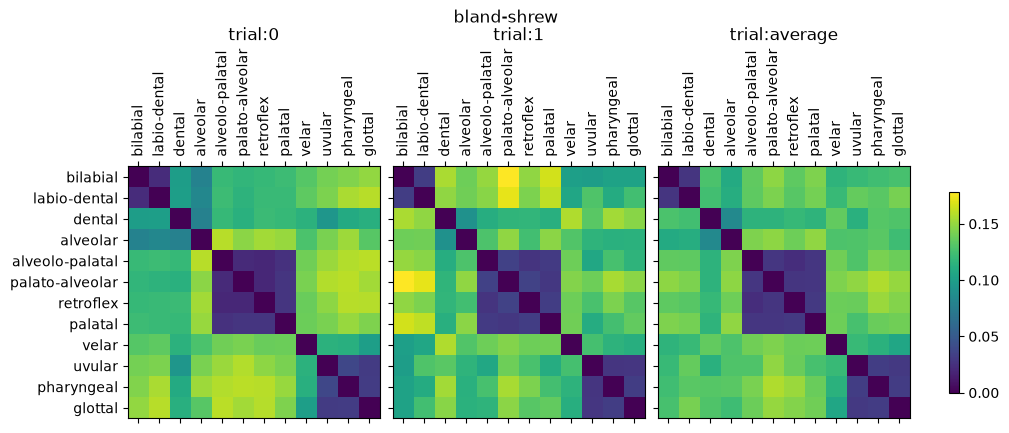

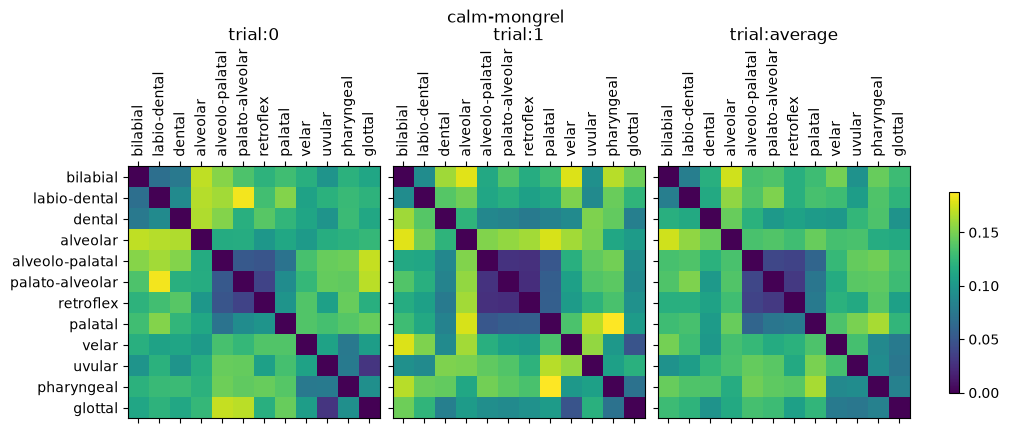

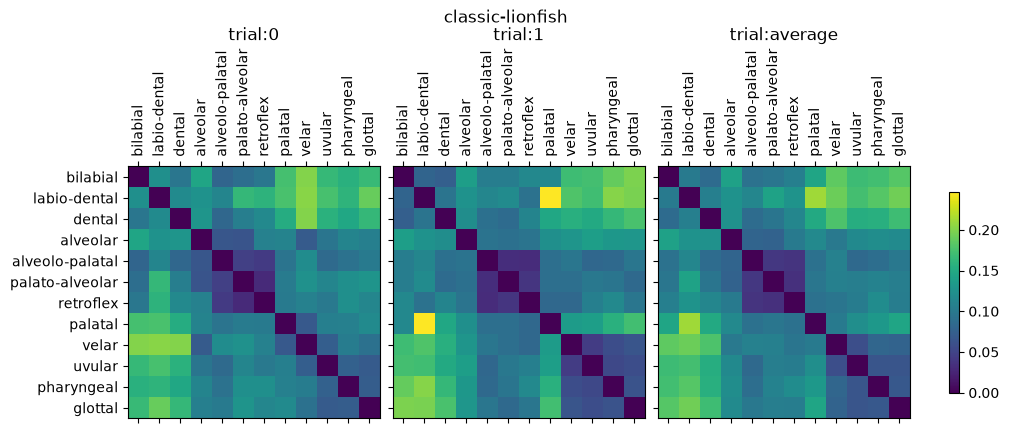

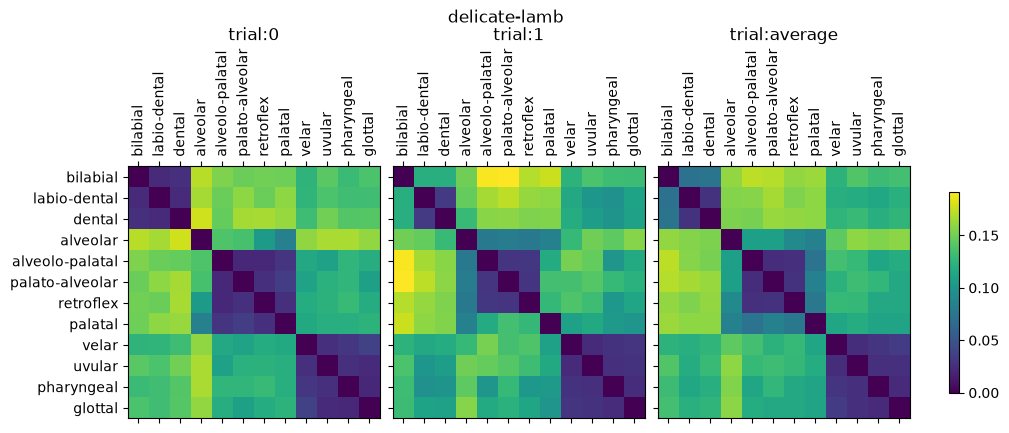

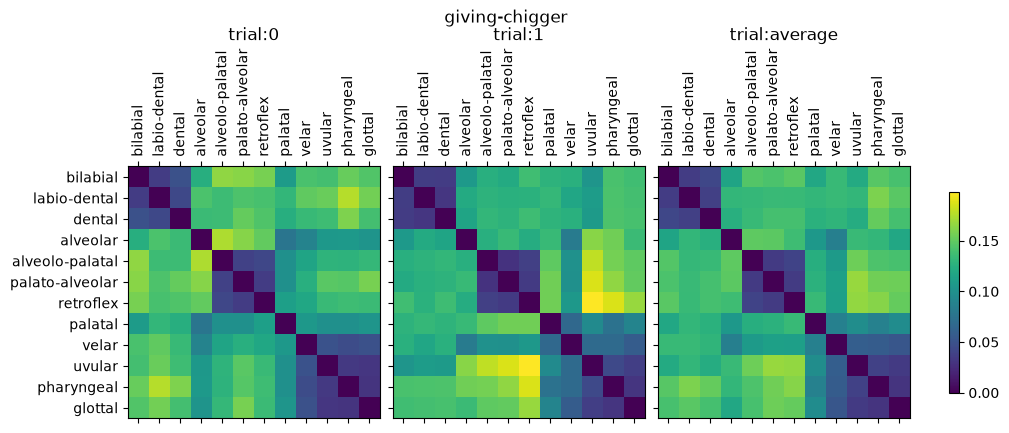

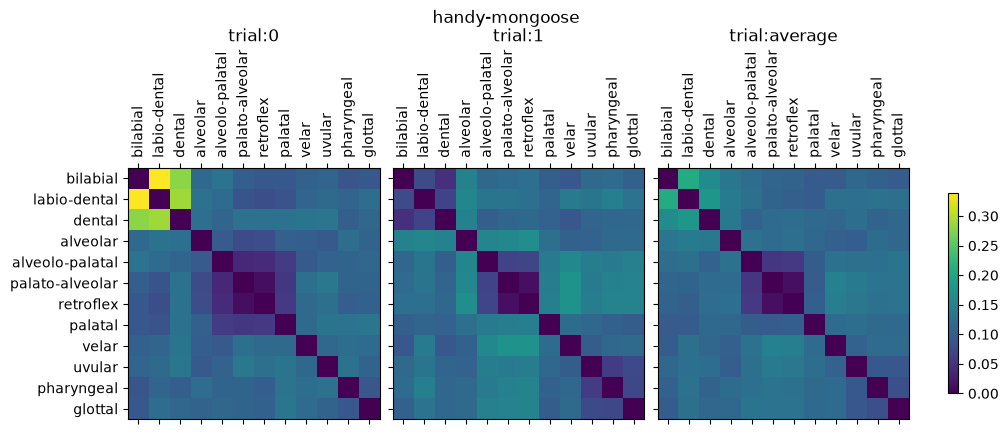

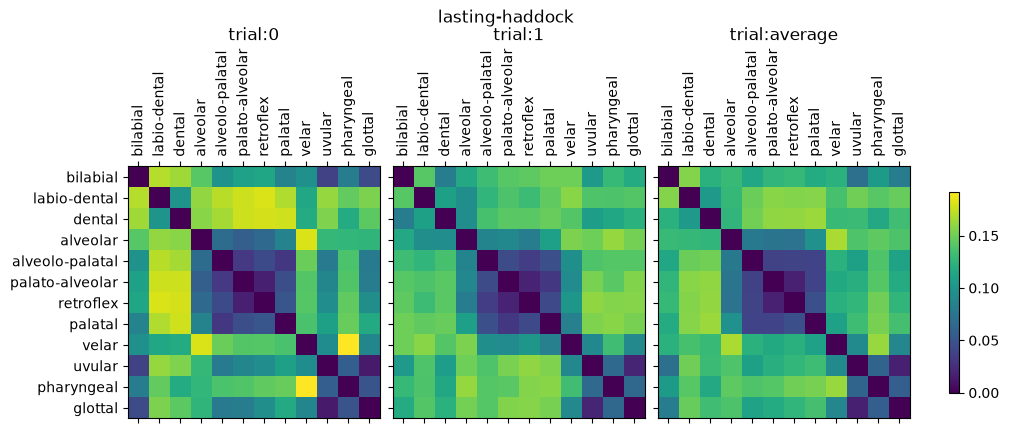

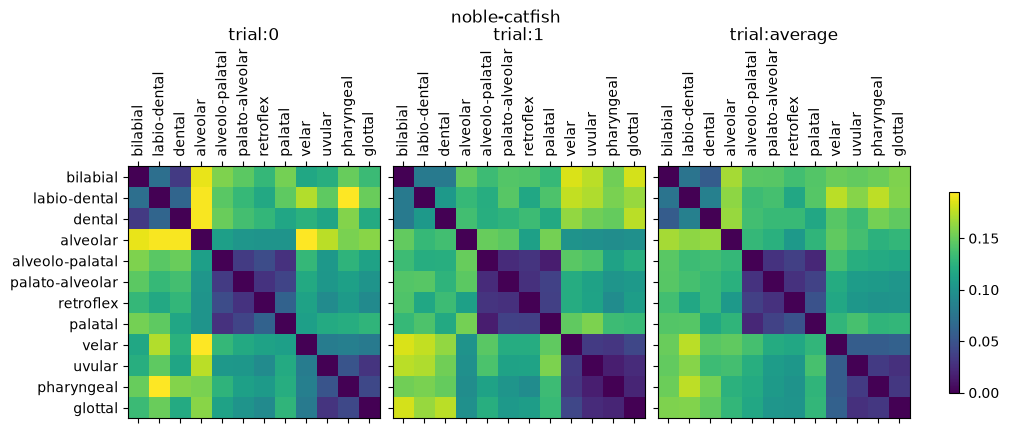

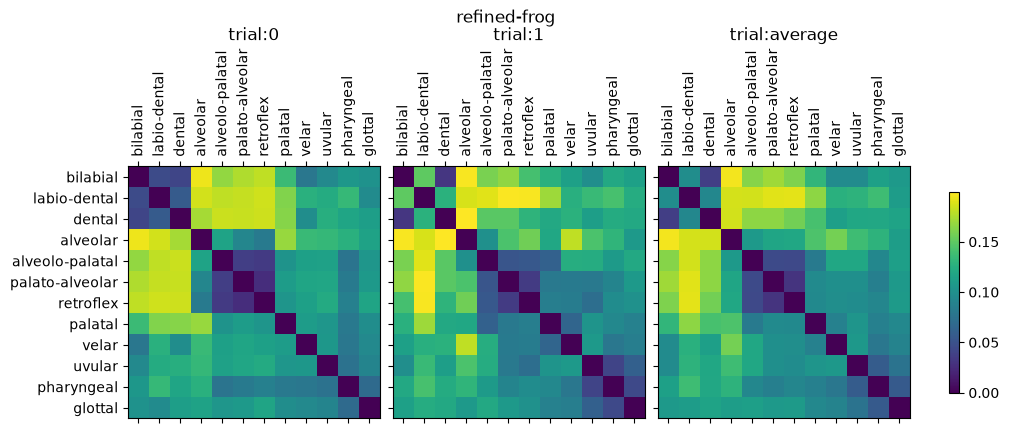

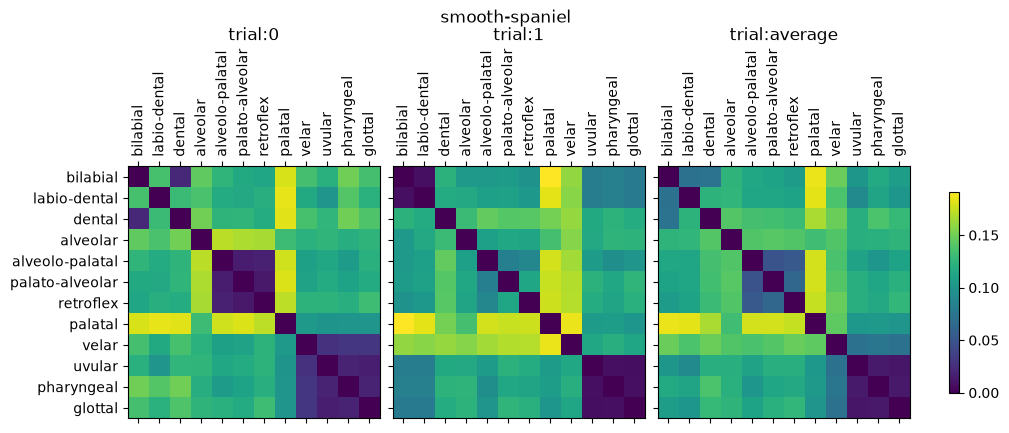

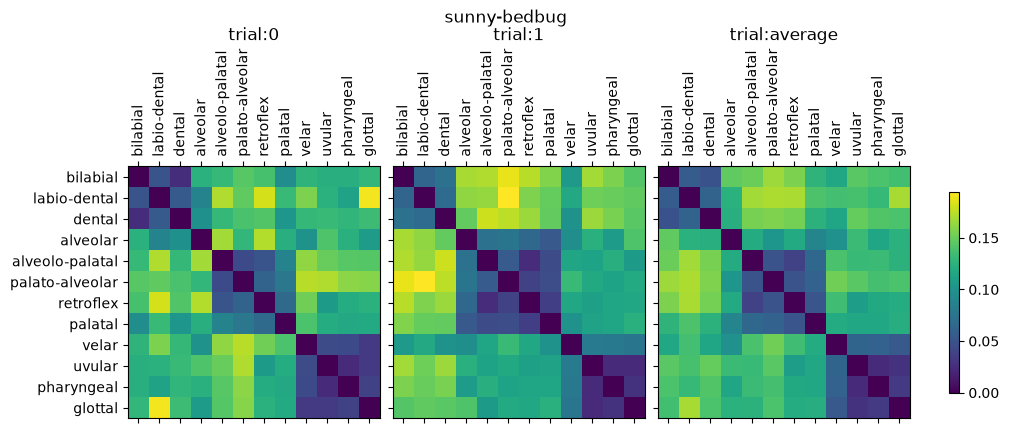

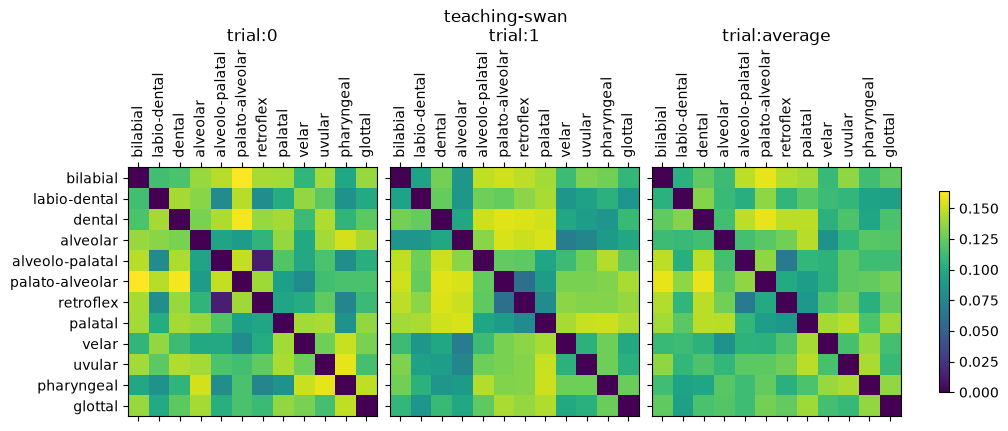

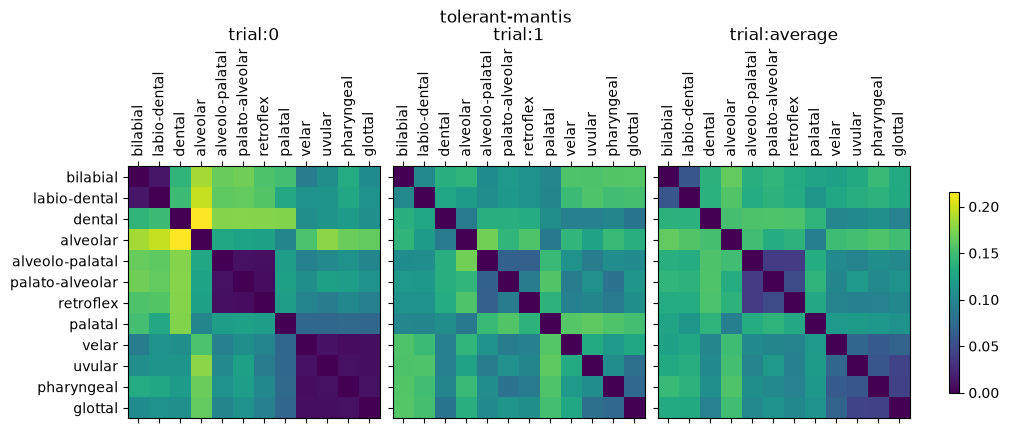

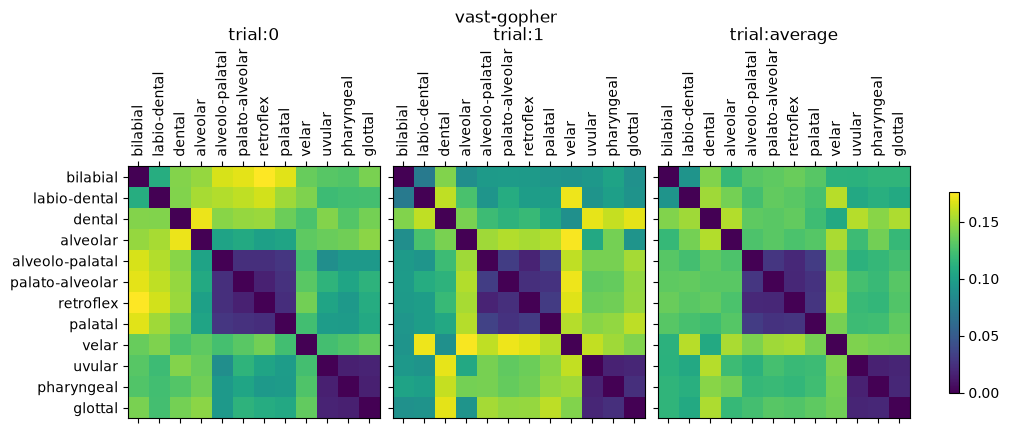

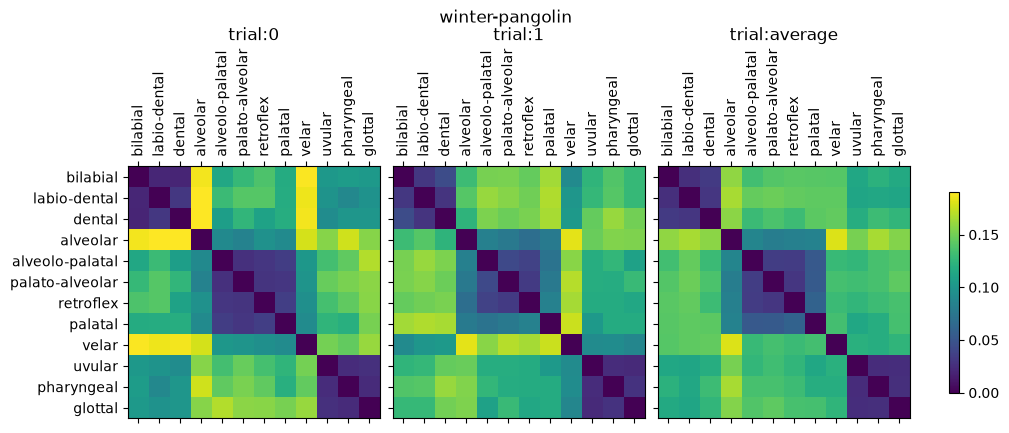

In [7]:
for subject, subj_df in distance_df.groupby('subject'):

    # Add the trial averages
    avg_df = subj_df.groupby(['fricative1', 'fricative2', 'subject', 'version']).mean().reset_index().assign(trial = 'average')
    subj_df = pd.concat([subj_df, avg_df])

    # Now we do the plotting
    num_trials = len(pd.unique(subj_df['trial']))
    
    fig, axes = plt.subplots(1, num_trials, figsize=(10, 5), constrained_layout=True)

    vmin = 0
    vmax = subj_df['distance'].max().item()
    for idx, (trial, df) in enumerate(subj_df.groupby('trial')):
        ax = axes[idx]
        stimuli_names, rdm = distance_matrix_from_df(df)
        cax = ax.matshow(rdm, cmap = 'viridis', vmin=vmin, vmax=vmax)
    
        # Set tick positions first, then labels
        ax.set_xticks(range(len(stimuli_names)), labels = stimuli_names, rotation="vertical")
        if idx == 0:
            ax.set_yticks(range(len(stimuli_names)))
            ax.set_yticklabels(stimuli_names)
        else:
            ax.set_yticks(range(len(stimuli_names)))
            ax.set_yticklabels('')
        ax.set_title(f"trial:{trial}")
    
    fig.suptitle(f"{subject}", y = 1.02)
    fig.colorbar(cax, ax=axes, shrink=0.45)                 # one colorbar, attached to all axes

    plt.show()

The next cell makes and saves a sample distance matrix for the paper. 
We use the subject with alias `delicate-lamb` because they have a typical intertrial correlation (more on that below). 

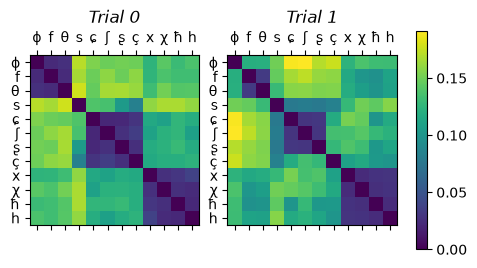

In [8]:
plot_subjects = ['delicate-lamb']

include_averages = False
n_cols = 3 if include_averages else 2
n_rows = len(plot_subjects)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(7*(n_cols/3), 9*(n_rows/3)), constrained_layout=True, squeeze=False)

for subject, subj_df in distance_df.groupby('subject'):
    if subject not in plot_subjects:
        continue
    # Add the trial averages
    if include_averages:
        avg_df = subj_df.groupby(['fricative1', 'fricative2', 'subject', 'version']).mean().reset_index().assign(trial = 'average')
        subj_df = pd.concat([subj_df, avg_df])

    # Now we do the plotting
    num_trials = len(pd.unique(subj_df['trial']))

    rownum = plot_subjects.index(subject)
    axrow = axes[rownum]
    
    vmin = 0
    vmax = subj_df['distance'].max().item()
    for colnum, (trial, df) in enumerate(subj_df.groupby('trial')):
        ax = axrow[colnum]
        stimuli_names, rdm = distance_matrix_from_df(df)
        cax = ax.matshow(rdm, cmap = 'viridis', vmin=vmin, vmax=vmax)
    
        # Set tick positions first, then labels
        ax.set_xticks(range(len(stimuli_names)), labels = [fric_symbols[name] for name in stimuli_names], rotation="horizontal")
        ax.set_yticks(range(len(stimuli_names)))
        ax.set_yticklabels([fric_symbols[name] for name in stimuli_names])
        ax.set_title(f"Trial {trial}", style="italic")
        if colnum == 0 and n_rows > 1:
            ax.set_ylabel(f"{subject}", style="italic")

if n_rows > 1:    
    fig.suptitle(f"Sample distance matrices", fontweight="bold")
    fig.supylabel("Subject", fontweight="bold")
    
fig.colorbar(cax, ax=axes, shrink=0.75)                 # one colorbar, attached to all axes

if SAVE_FIGURE_MODE:
    fig.savefig(FIGURE_DIR / 'icphs_rdms.png')
plt.show()

# Distribution of stimilarity metrics

The Meadows platform scales each dissimilarity set according to the Kriegeskorte and Mur (2012) procedure, so the distances should be all on the same scale. 
The plots below show histograms of the distances for each participant.

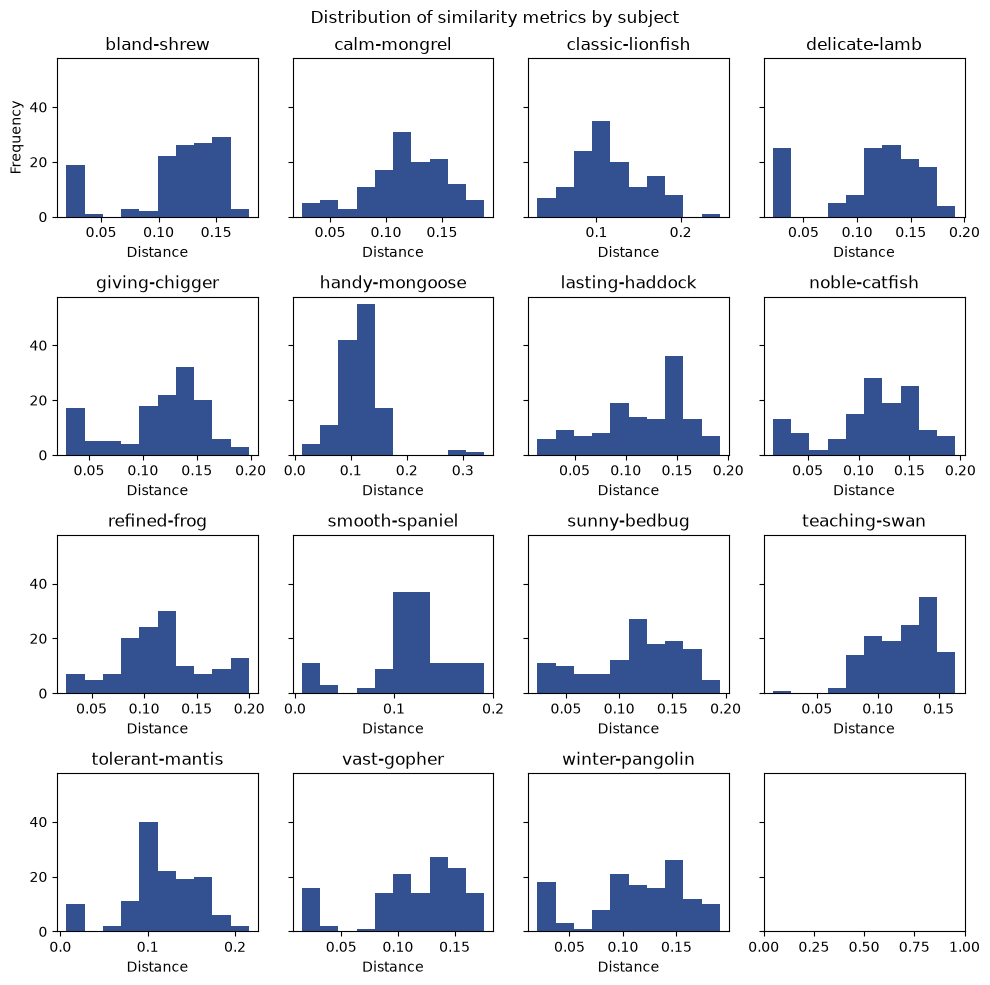

In [9]:
n_rows = -(-distance_df['subject'].nunique() // 4)
fig, axes = plt.subplots(n_rows, 4, figsize=(10, 2.5*n_rows), sharey=True)
fig.suptitle("Distribution of similarity metrics by subject")

for idx, (subject, df) in enumerate(distance_df.groupby('subject')):
    ax = axes[idx // 4, idx % 4]
    ax.hist(df['distance'], alpha = 0.8, bins=10)
    ax.set_title(f"{subject}")
    ax.set_xlabel("Distance")
    if idx == 0:
        ax.set_ylabel("Frequency")

plt.tight_layout()

plt.show()

Let's take a look at the overall distribution, across all subjects and trials. 

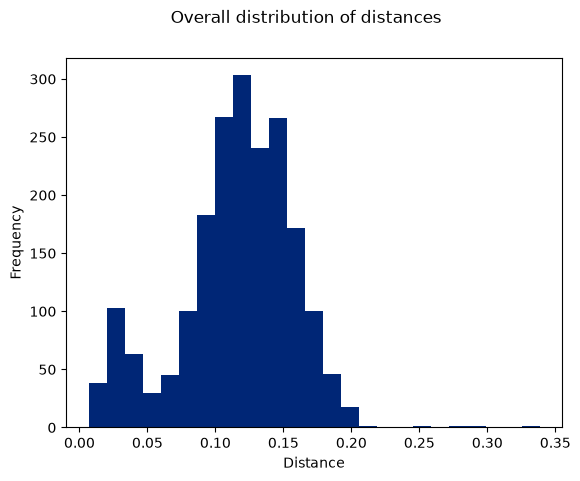

In [10]:
fig, ax = plt.subplots()
fig.suptitle("Overall distribution of distances")

ax.hist(distance_df['distance'], bins=25)
ax.set_xlabel("Distance")
ax.set_ylabel("Frequency")
plt.show()

There are a few outliers above 0.25; looking at the by-subject histograms, these all come from `handy-mongoose`.
The distribution is bimodal, with one peak between 0 and 0.05 and another peak around 0.15.
The lower peak is consistent with subjects finding a subset of stimuli very similar.

## Within-subject consistency + data filtering

Looking at the correlations between Trial 0 and Trial 1 distances within each subject tells us how consistent the distance measurements were.

If there's no relationship, there could be a couple explanations: the participant may not have had good audio (especially for v2 participants who had no headphone check); they may not have been paying attention; or they may not have been able to hear the differences.

In the plots below, each point represents a fricative pair. 
Its x-coordinate is the perceptual distance generated in Trial 0, and its y-coordinate is the perceptual distance generated in Trial 1.
If the distances for a given pair are exactly the same from Trial 0 to Trial 1, the point representing that pair will lie on the line y=x, which is marked with a dashed line below.
The correlation between the Trial 0 and Trial 1 distances is printed beneath each subject's alias.

In [11]:
distance_df.head()

,fricative1,fricative2,distance,subject,trial,version
0,Voiceless_alveolar_sibilant,Voiceless_alveolo-palatal_sibilant,0.095889,teaching-swan,0,2
1,Voiceless_alveolar_sibilant,Voiceless_bilabial_fricative,0.138335,teaching-swan,0,2
2,Voiceless_alveolar_sibilant,Voiceless_dental_fricative,0.130552,teaching-swan,0,2
3,Voiceless_alveolar_sibilant,Voiceless_glottal_fricative,0.141599,teaching-swan,0,2
4,Voiceless_alveolar_sibilant,Voiceless_labio-dental_fricative,0.134661,teaching-swan,0,2


Text(0.5, 0.01, 'Trial 0 distance')

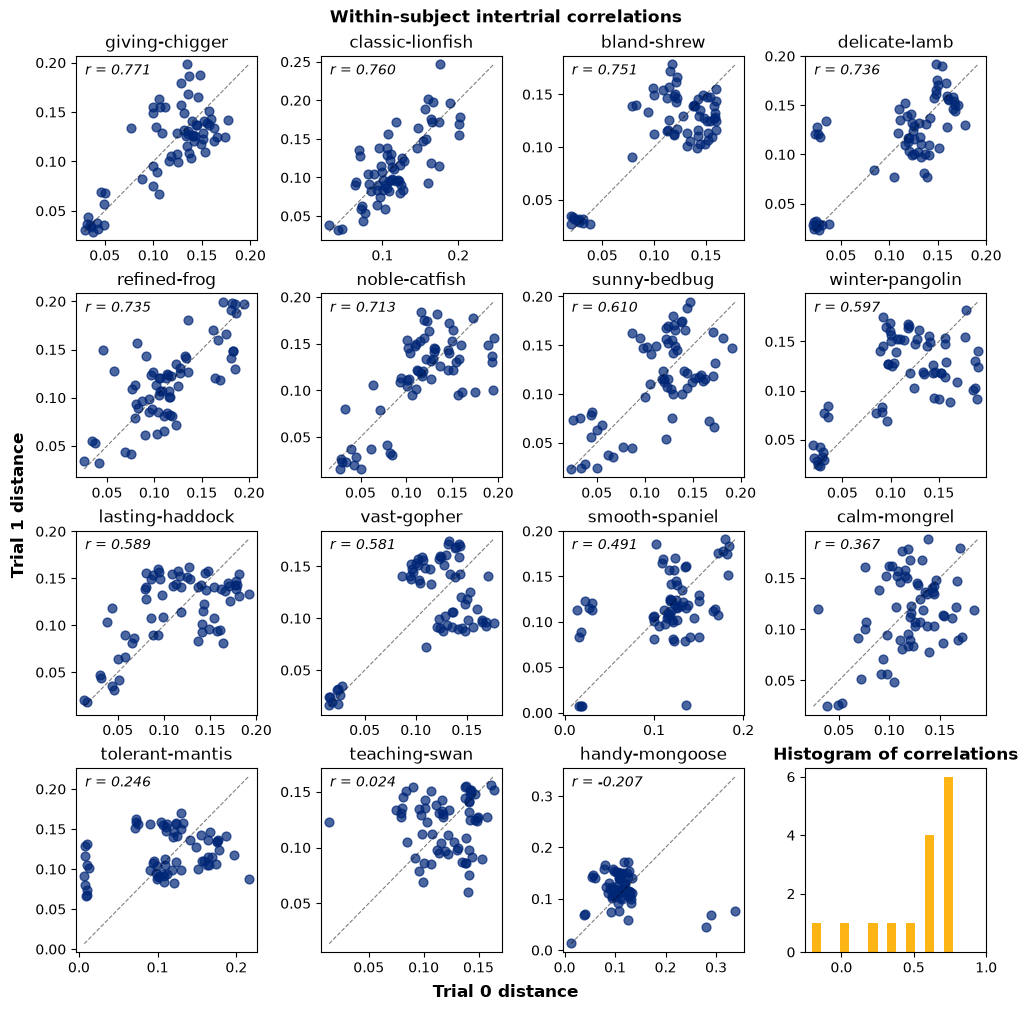

In [12]:
correlations = {}

for subject, df in distance_df.groupby('subject'):
    trials = df[['fricative1', 'fricative2', 'distance', 'trial']].pivot(index=['fricative1', 'fricative2'], columns='trial', values='distance')
    trial0_distances = trials[0]
    trial1_distances = trials[1]
    r = trial0_distances.corr(trial1_distances)
    correlations[subject] = r
    
n_row = -(-distance_df['subject'].nunique() // 4)



fig, axes = plt.subplots(n_row, 4, sharex = False, figsize = (10, 2.5*n_row), constrained_layout=True)

for idx, (subject, df) in enumerate(distance_df.sort_values('subject', key=lambda x: x.apply(correlations.get), ascending=False).reset_index(drop=True).groupby('subject', sort=False)):
    ax = axes[idx // 4, idx % 4]
    trials = df[['fricative1', 'fricative2', 'distance', 'trial']].pivot(index=['fricative1', 'fricative2'], columns='trial', values='distance')
    trial0_distances = trials[0]
    trial1_distances = trials[1]

    ax.scatter(trial0_distances, trial1_distances, s=40, alpha=0.7)
    lo = df['distance'].min().min()
    hi = df['distance'].max().max()
    ax.plot([lo, hi], [lo, hi], 'k--', linewidth=0.8, alpha=0.5)
    r = correlations[subject]
    ax.set_title(f'{subject}',)
    ax.annotate(f"r = {r:.3f}", xy = (.05, .9), xycoords='axes fraction', style="italic")
    # if idx // 4 == 1:
    # ax.set_xlabel('Trial 0', style="italic")
    # ax.set_ylabel('Trial 1', style="italic")

ax = axes[n_row-1, 3]
ax.hist(correlations.values(), bins=15, color = '#FDB515')
ax.set_xlim(-0.25, 1)
ax.set_title("Histogram of correlations", fontweight='bold',)
fig.suptitle("Within-subject intertrial correlations", fontweight="bold")
fig.supylabel("Trial 1 distance", fontweight = "bold")
fig.supxlabel("Trial 0 distance", fontweight = "bold")

A clear correlation is present for most of the subjects.
Visual inspection suggests that the participants with correlations below 0.3 (`handy-mongoose`, `tolerant-mantis`, `teaching-swan`) have so little between-trial consistency that their data might be meaningless.

Two of those subjects, `teaching-swan` and `handy-mongoose`, are from the version 2 experiment and didn't complete a headphones check, so their problem could have been the audio system. The last one, `tolerant-mantis`, is interesting because there's a lot of variation in Trial 0 and not much in Trial 1, suggesting that they might have lost interest in the task. 
Looking at `tolerant-mantis`'s distance matrices provides a bit more evidence for this hypothesis: the Trial 0 matrix has structure (i.e., blocks along the diagonal indicating groupings by anteriority) that vanishes in Trial 1.

More generally, all three of these participants have _restricted ranges_ in one or both of the trials.
The restricted ranges show that the subjects didn't use the entire arena to place the stimuli---i.e., they didn't do the experiment correctly.
Based on this reasoning, I pick 0.3 as the cutoff for including a subject's data in the experiment.
The next cell removes `handy-mongoose`, `tolerant-mantis`, and `teaching-swan` from the DataFrame.

In [13]:
corr_cutoff = 0.3
included_subjects = [k for k in correlations.keys() if correlations[k] > 0.3]

distance_df = distance_df.loc[lambda x: x['subject'].isin(included_subjects)].reset_index(drop=True)
print(f"Remaining subjects in distance_df: {distance_df['subject'].unique().tolist()}")

Remaining subjects in distance_df: ['giving-chigger', 'calm-mongrel', 'winter-pangolin', 'sunny-bedbug', 'lasting-haddock', 'smooth-spaniel', 'classic-lionfish', 'vast-gopher', 'refined-frog', 'noble-catfish', 'delicate-lamb', 'bland-shrew']


The next cell saves `noble-catfish`'s plot for the paper.

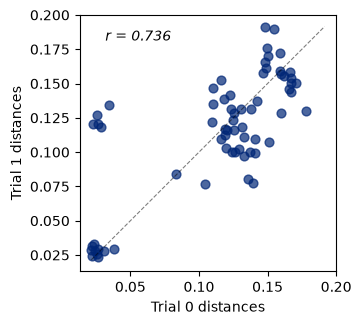

In [14]:
fig, ax = plt.subplots(constrained_layout=True, figsize=(3.5, 3.5))
ax.set_aspect('equal')
subject = plot_subjects[0]

subject_df = distance_df.query('subject == @subject')
trials = subject_df[['fricative1', 'fricative2', 'distance', 'trial']].pivot(index=['fricative1', 'fricative2'], columns='trial', values='distance')
trial0_distances = trials[0]
trial1_distances = trials[1]    

ax.scatter(trial0_distances, trial1_distances, s=40, alpha=0.7)
lo = subject_df['distance'].min().min()
hi = subject_df['distance'].max().max()
ax.plot([lo, hi], [lo, hi], 'k--', linewidth=0.8, alpha=0.5)
r = correlations[subject]
ax.annotate(f"r = {r:.3f}", xy = (.1, .9), xycoords='axes fraction', style="italic")
ax.set_xlabel("Trial 0 distances")
ax.set_ylabel("Trial 1 distances")
if SAVE_FIGURE_MODE: 
    fig.savefig(FIGURE_DIR / 'icphs_correlations.png')
plt.show()

## Determining the proper dimensions for multidimensional scaling

We can use the distance matrices to perform multidimensional scaling (MDS), but the MDS algorithm requires pre-setting the number of dimensions.

A principled way to set this sort of hyperparameter is a scree plot and elbow test, which are used for principal components analysis and k-means clustering. 
The hyperparameter of interest (here, number of dimensions) is plotted on the x-axis, and a cost function/badness-of-fit metric is plotted on the y-axis. 
Then, the optimal hyperparameter is set at the elbow of the graph, where an increment to the hyperparameter has much less effect than the previous increment.

The MDS algorithm minimizes a cost function called _stress_, ready-made for this type of plot.
The cell below performs MDS on each subject-trial combination for dimension hyperparameters 1 through 5 and stores the final (normalized) stress metric.
The following cells calculate MDS stress and produce scree plots for each subject.

In [15]:
stress_df = []

for (subject, trial), df in distance_df.drop('version', axis = 'columns').groupby(['subject', 'trial']):
    _, rdm = distance_matrix_from_df(df)
    for i in range(1, 6):
        mds = MDS(n_components=i, n_init = 1, metric="precomputed", normalized_stress = True, random_state=SEED, init="random").fit(rdm)
        stress_df.append((subject, i, trial, mds.stress_))

stress_df = pd.DataFrame(stress_df, columns = ['subject', 'n_dim', 'trial', 'MDS stress'])
stress_df.pivot(index='n_dim', values='MDS stress', columns=['subject', 'trial'])

subject bland-shrew           calm-mongrel           classic-lionfish  \
trial             0         1            0         1                0   
n_dim                                                                   
1          0.815158  0.763388     0.691623  0.472429         0.647223   
2          0.134077  0.164474     0.242407  0.151986         0.201582   
3          0.072168  0.086998     0.109685  0.074742         0.098129   
4          0.033166  0.037373     0.076333  0.041413         0.061552   
5          0.023093  0.027328     0.054879  0.032640         0.045645   

subject           delicate-lamb           giving-chigger            ...  \
trial           1             0         1              0         1  ...   
n_dim                                                               ...   
1        0.599745      0.779363  0.698789       0.585558  0.714842  ...   
2        0.170638      0.096076  0.154652       0.131822  0.170670  ...   
3        0.105883      0.043048  0.074320       0.062510  0.072504  ...   
4        0.087708      0.034765  0.048359       0.033792  0.051000  ...   
5        0.077465      0.031408  0.044842       0.026843  0.048364  ...   

subject refined-frog           smooth-spaniel           sunny-bedbug  \
trial              0         1              0         1            0   
n_dim                                                                  
1           0.748395  0.578406       0.640246  0.674829     0.708483   
2           0.138854  0.161244       0.152849  0.215027     0.169308   
3           0.078770  0.094146       0.067870  0.127484     0.081899   
4           0.043259  0.053450       0.037658  0.081130     0.066571   
5           0.031927  0.044615       0.030951  0.057217     0.063822   

subject           vast-gopher           winter-pangolin            
trial           1           0         1               0         1  
n_dim                                                              
1        0.789716    0.732115  0.807710        0.708642  0.823793  
2        0.119943    0.213655  0.134379        0.132428  0.116812  
3        0.054088    0.110022  0.081520        0.059329  0.046946  
4        0.036162    0.046963  0.049092        0.052937  0.032671  
5        0.029137    0.024695  0.045892        0.049517  0.021568  

[5 rows x 24 columns]

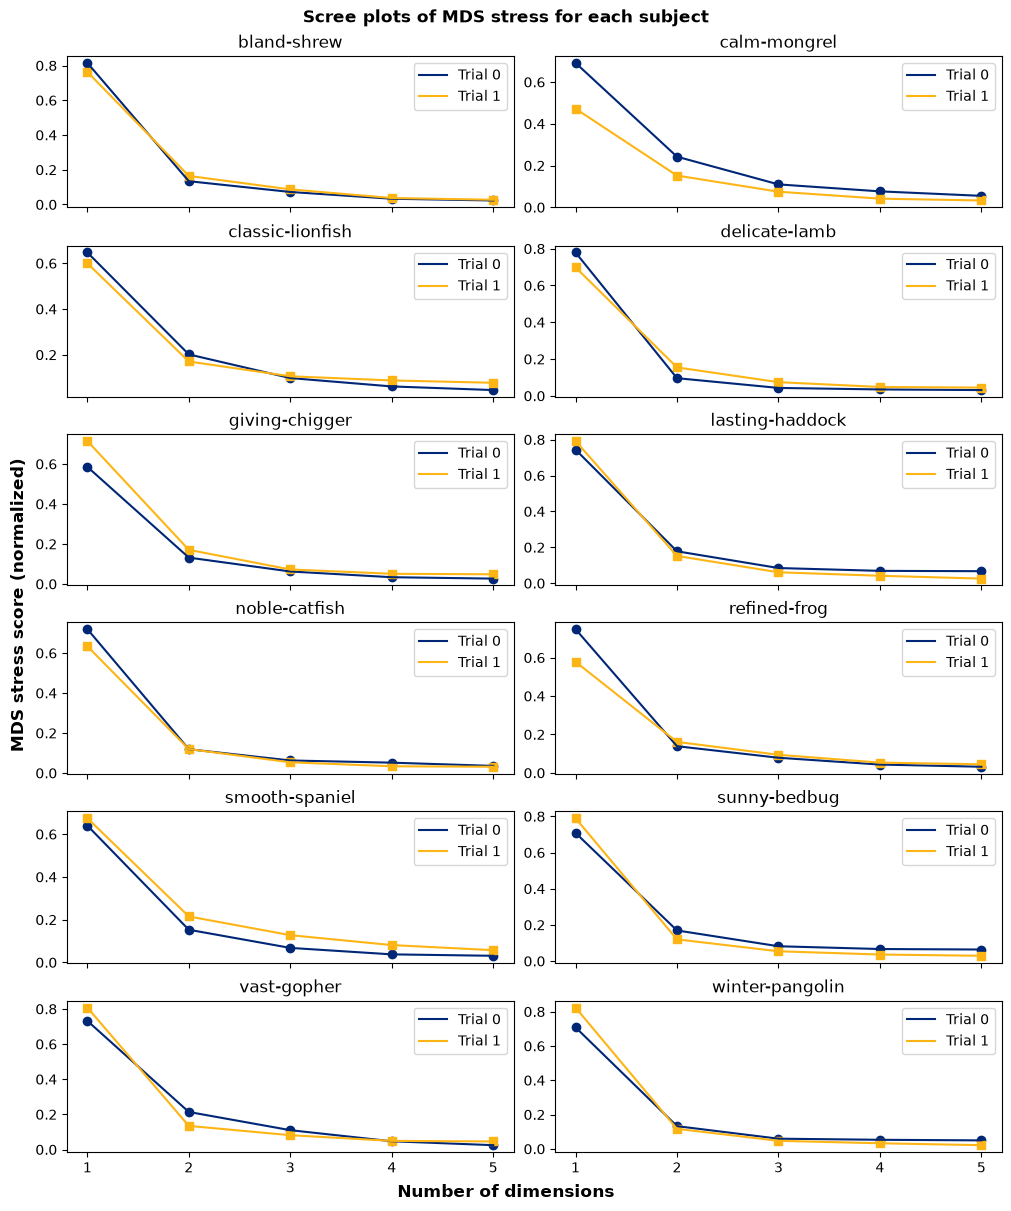

In [16]:
n_plots = stress_df['subject'].nunique() // 2
fig, axes = plt.subplots(n_plots, 2, sharex = True, figsize = (10, n_plots*2), constrained_layout=True)

for i, (subject, df) in enumerate(stress_df.groupby('subject')):
    ax = axes[i // 2, i % 2]
    ax.scatter(df.query("trial==0")['n_dim'], df.query("trial==0")['MDS stress'], marker ='o')
    ax.plot(df.query("trial==0")['n_dim'], df.query("trial==0")['MDS stress'], label="Trial 0")
    ax.scatter(df.query("trial==1")['n_dim'], df.query("trial==1")['MDS stress'], marker ='s')
    ax.plot(df.query("trial==1")['n_dim'], df.query("trial==1")['MDS stress'], label="Trial 1")
    ax.legend()
    ax.set_title(f"{subject}")
ax.set_xticks(range(1, 6))
fig.supxlabel("Number of dimensions", fontweight="bold")
fig.supylabel("MDS stress score (normalized)", fontweight="bold")
fig.suptitle("Scree plots of MDS stress for each subject", fontweight="bold")
plt.show()

The elbow for each input occurs at 2 dimensions.


## Multidimensional scaling

Now we plot perceptual fricative space, as determined for each subject/trial.
First we actually perform the MDS:

In [30]:
mds_data = []
for (subject, trial), df in distance_df.drop('version', axis = 'columns').groupby(['subject', 'trial']):
    stimuli_names, rdm = distance_matrix_from_df(df)
    mds = MDS(n_components=2, n_init = 1, metric="precomputed", normalized_stress = True, random_state=SEED, init="random").fit(rdm)
    embedding = pd.DataFrame(mds.embedding_)
    embedding['label'] = stimuli_names
    embedding['subject'] = subject
    embedding['trial'] = trial
    mds_data.append(embedding)
mds_data = pd.concat(mds_data, axis='rows')

mds_data.head()

,0,1,label,subject,trial
0,-0.066325,-0.037885,bilabial,bland-shrew,0
1,-0.076688,-0.033389,labio-dental,bland-shrew,0
2,0.000033,-0.040558,dental,bland-shrew,0
3,-0.036565,-0.088609,alveolar,bland-shrew,0
4,-0.035283,0.076644,alveolo-palatal,bland-shrew,0


The cell below plots the raw outputs:

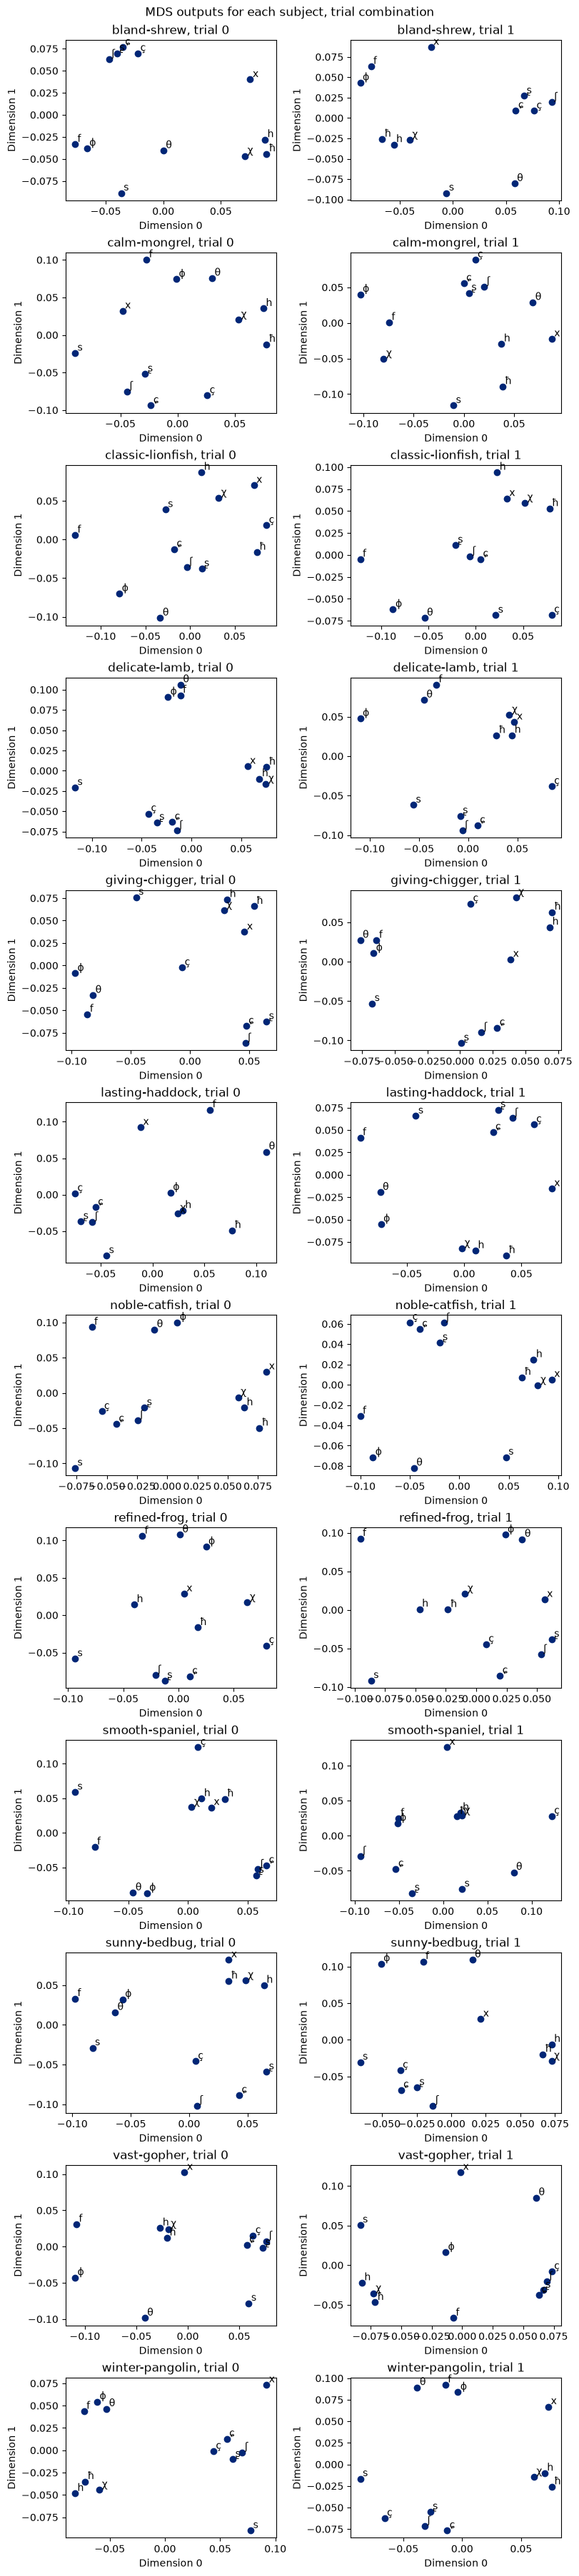

In [31]:
fric_symbols = {label: val for idx, label, val in fricative_df[['fricative_label', 'fricative']].itertuples()}
n_rows = mds_data['subject'].nunique()
fig, axes = plt.subplots(n_rows, 2, figsize=(8, 3*n_rows), constrained_layout=True)

for i, ((subject, trial), df) in enumerate(mds_data.groupby(['subject', 'trial'])):
    ax = axes[i // 2, i % 2]
    ax.scatter(df[0], df[1])
    for label, x, y in zip(df['label'], df[0], df[1]):
        ax.annotate(fric_symbols[label], (x, y), xytext=(2.5,2.5), textcoords='offset points')
    ax.set_title(f"{subject}, trial {trial}")
    ax.set_xlabel("Dimension 0")
    ax.set_ylabel("Dimension 1")
fig.suptitle("MDS outputs for each subject, trial combination")

plt.show()

MDS doesn't care about matching the dimensions across instances, so the spaces are all rotated and we can't see commonalities clearly.
The fix is _generalized Procrustes analysis_, performed by the `gpa` function below. 
The function takes one set of points as an initial condition and finds a transformation to align it with all the other sets of points as closely as possible, using only rotations, translations, reflections, and uniform scaling. 
In other words, it keeps the relationship between points the same but matches the spaces as closely as possible. 
The algorithm then takes the average of all the aligned sets and performs another round of alignment.
Eventually, the spaces are close enough to the average that they clear a tolerance threshold, and the result is a set of aligned graphs and an average we can use to explore fricative space. 

The next two cells perform this process and store the results in `aligned_df` and `mean`. 
Then the aligned spaces are plotted.

In [32]:
matrices = {
    (subject, int(trial)): df.sort_values('label')[[0, 1]].to_numpy()
    for (subject, trial), df in mds_data.groupby(['subject', 'trial'])
}
sorted_order = sorted(mds_data['label'].unique())

In [33]:
keys = matrices.keys()
unaligned = matrices.values()
aligned, mean, distances = gpa(unaligned)
aligned_df = []
for (subject, trial), m, in zip(keys, aligned,):
    df = pd.DataFrame(m)
    df['label'] = sorted_order
    df['subject'] = subject
    df['trial'] = trial
    aligned_df.append(df)
aligned_df = pd.concat(aligned_df, axis='rows')
aligned_df

Concluded after 12 iterations


,0,1,label,subject,trial
0,-0.114904,-0.314709,alveolar,bland-shrew,0
1,-0.134273,0.262557,alveolo-palatal,bland-shrew,0
2,-0.226150,-0.141871,bilabial,bland-shrew,0
3,0.005968,-0.141630,dental,bland-shrew,0
4,0.312310,-0.085357,glottal,bland-shrew,0
...,...,...,...,...,...
7,-0.057354,0.266032,palato-alveolar,winter-pangolin,1
8,0.277743,0.034541,pharyngeal,winter-pangolin,1
9,-0.053504,0.206989,retroflex,winter-pangolin,1
10,0.217905,0.005669,uvular,winter-pangolin,1


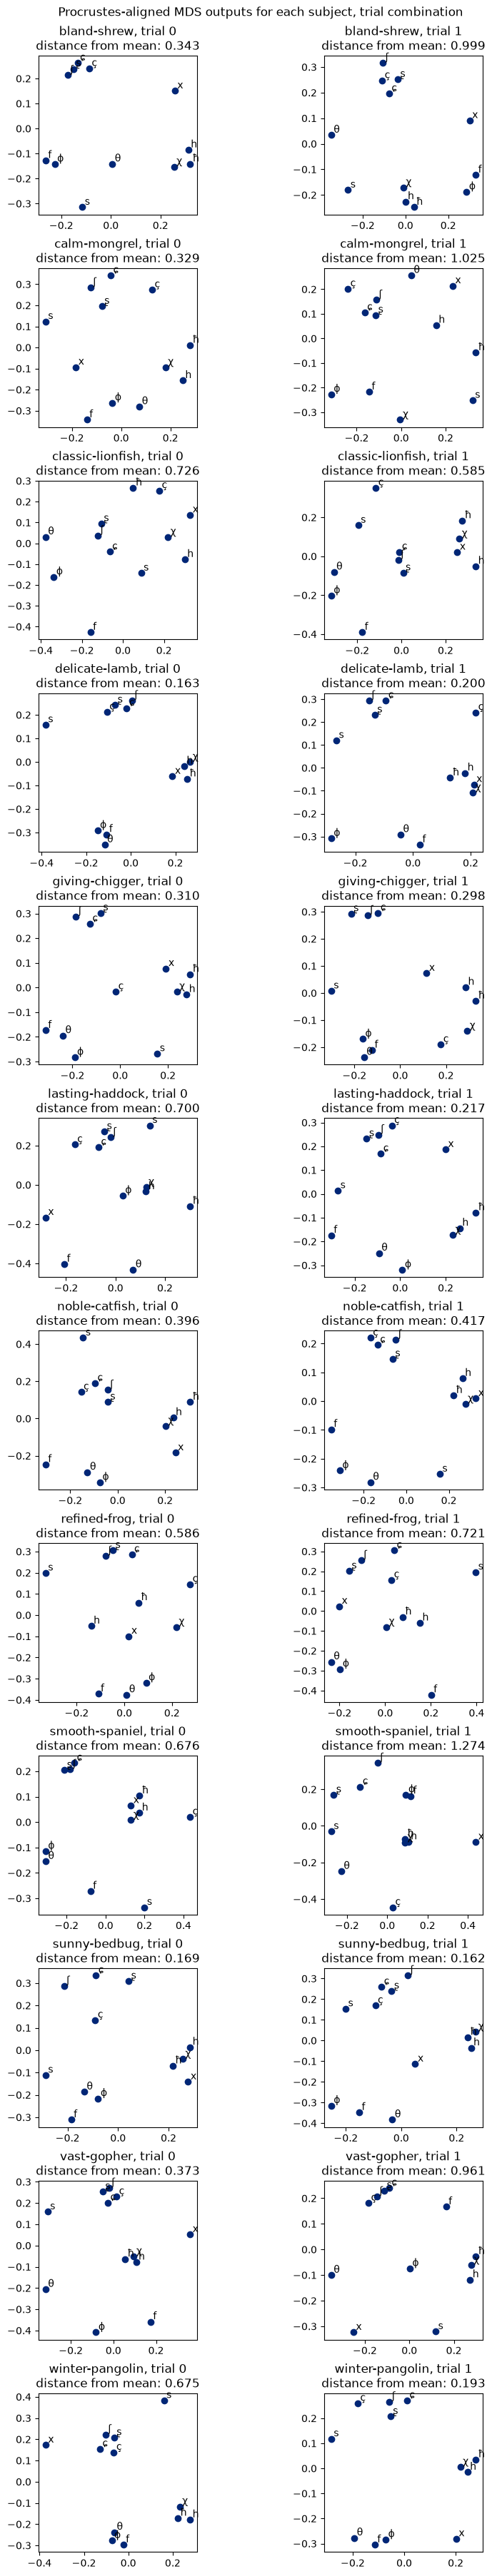

In [34]:
distance_dict = {alias: distance for alias, distance in zip(keys, distances)}
n_rows = aligned_df['subject'].nunique()

fig, axes = plt.subplots(n_rows, 2, figsize=(8, 3*n_rows), constrained_layout=True)

for i, ((subject, trial), df) in enumerate(aligned_df.groupby(['subject', 'trial'])):
    ax = axes[i // 2, i % 2]
    ax.set_box_aspect(1)
    ax.scatter(df[0], df[1])
    distance = distance_dict[(subject, trial)]
    for label, x, y in zip(df['label'], df[0], df[1]):
        ax.annotate(fric_symbols[label], (x, y), xytext=(2.5,2.5), textcoords='offset points')
    ax.set_title(f"{subject}, trial {trial}\ndistance from mean: {distance:0.3f}")
fig.suptitle("Procrustes-aligned MDS outputs for each subject, trial combination")
plt.show()

The cell below graphs the `noble-catfish` sample spaces for the paper.

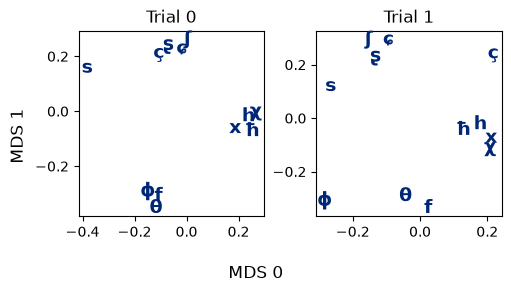

In [35]:
n_rows = len(plot_subjects)

fig, axes = plt.subplots(n_rows, 2, figsize=(5, 3*n_rows), constrained_layout=True, squeeze=False)

for i, ((subject, trial), df) in enumerate(aligned_df.query('subject in @plot_subjects').groupby(['subject', 'trial'])):
    if subject in plot_subjects:
        ax = axes[i // 2, i % 2]
        ax.set_box_aspect(1)
        ax.scatter(df[0], df[1], s=0)
        distance = distance_dict[(subject, trial)]
        for label, x, y in zip(df['label'], df[0], df[1]):
            ax.annotate(fric_symbols[label], (x, y), ha="center", va="center", fontsize=14, color='#002676', fontweight="bold")
        ax.set_title(f"Trial {trial}")
    
# fig.suptitle("Procrustes-aligned MDS outputs for each subject, trial combination")
fig.supxlabel("MDS 0")
fig.supylabel("MDS 1")
if SAVE_FIGURE_MODE:
    fig.savefig(FIGURE_DIR / "icphs_subjectspace.png")
plt.show()

The next cell produces a graph of the average of all these fricative spaces.
In otherw words, it's the best-match perceptual space for our participants

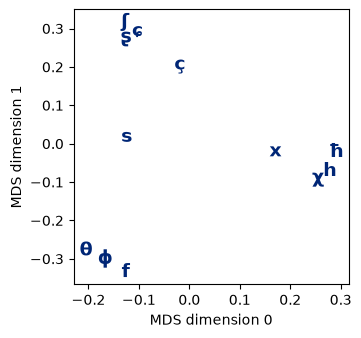

In [36]:
mean_df = pd.DataFrame(mean)
mean_df['label'] = sorted_order
fig, ax = plt.subplots(constrained_layout=True, figsize=(3.5, 3.5))
ax.set_box_aspect(1)
ax.scatter(mean_df[0], mean_df[1], s=0)
for label, x, y in zip(mean_df['label'], mean_df[0], mean_df[1]):
    ax.annotate(fric_symbols[label], (x, y), ha="center", va="center", fontsize=14, color='#002676', fontweight="bold")#, xytext=(2.5,2.5), textcoords='offset points')
# ax.set_title(f"Best match for all data", fontweight="bold")
ax.set_xlabel("MDS dimension 0")
ax.set_ylabel("MDS dimension 1")

plt.show()
if SAVE_FIGURE_MODE:
    fig.savefig(FIGURE_DIR / "icphs_bestmatch.png")

Statistical consultants on this project suggested that a principled way to show uncertainty around the MDS locations was to visualize how variable individual participant's MDS plots are compared to the average plot.
This is accomplished with the following plot, which shows each subject's contributions the locations visualized in the plot above.

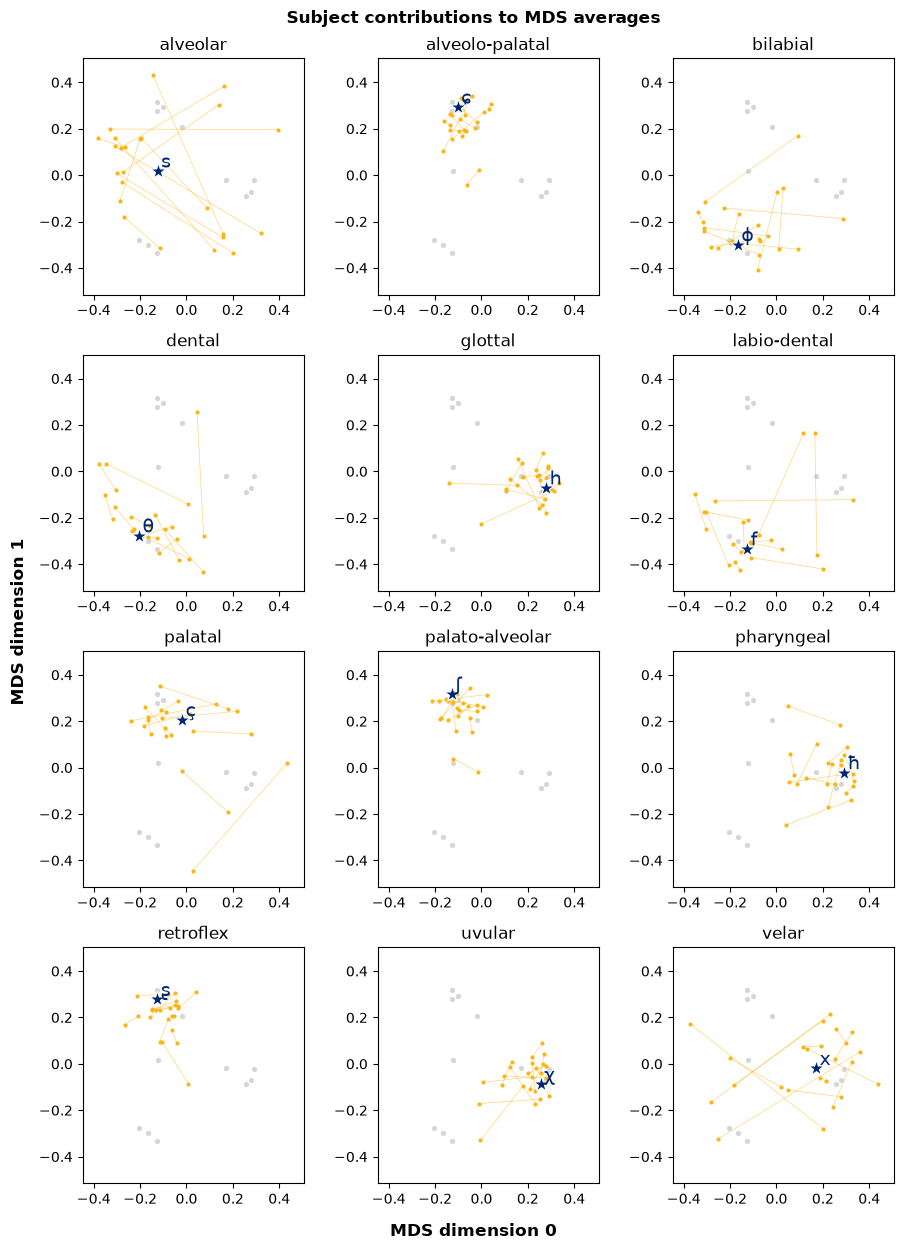

In [37]:
fig, ax = plot_mds_small_multiples(aligned_df, mean_df, symdict = fric_symbols, label_offset=0.015)
fig.suptitle("Subject contributions to MDS averages", y=1.01, fontweight="bold")
fig.supxlabel("MDS dimension 0", fontweight="bold", y=-.015)
fig.supylabel("MDS dimension 1", fontweight="bold", x=-.015)

plt.show()

## Mapping perceptual space to acoustic space

So, what part of the speech signal do these dimensions correspond to?
We have a large menu of options, given in the array below, where they are z-scored.

In [40]:
numeric_cols = ['Fm', 'Am', 'AmpD', 'Fsec', 'Asec', 'COG', 'SD', 'Skew', 'Kurtosis', 'DCT0', 'DCT1', 'DCT2',
       'DCT3', 'fricative_dur', 'syllable_dur', 'vowel_dur']
fricative_scaled = fricative_df.copy()
fricative_scaled[numeric_cols] = (fricative_df[numeric_cols] - fricative_df[numeric_cols].mean()) / fricative_df[numeric_cols].std()
fricative_scaled

,fricative_label,Fm,Am,AmpD,Fsec,Asec,COG,SD,Skew,Kurtosis,...,DCT1,DCT2,DCT3,textgrid_name,fricative,fricative_dur,syllable,syllable_dur,vowel,vowel_dur
0,bilabial,-0.145792,-1.068662,-1.191812,-0.903467,-0.529855,-0.881659,-0.652889,0.445980,0.483694,...,0.659101,0.730428,0.392296,Voiceless_bilabial_fricative.TextGrid,ɸ,-0.405495,ɸa,0.457673,a,1.147994
1,labio-dental,2.345919,-0.061715,1.312612,1.373270,0.600209,1.980874,0.052850,-2.044034,-0.186739,...,-1.408535,-2.143745,1.456744,Voiceless_labio-dental_fricative.TextGrid,f,-1.527386,fa,-1.721458,a,-1.130904
2,dental,0.516897,-2.277777,-1.404883,0.607130,-1.772688,-0.235275,1.620937,-0.039224,-1.041154,...,-0.727800,0.163937,0.941111,Voiceless_dental_fricative.TextGrid,θ,-0.946505,θa,-0.476980,a,0.233004
3,alveolar,0.967526,0.854941,0.412514,0.491486,1.154944,1.916011,-0.211757,-1.657759,-0.782984,...,-1.979983,-1.309177,0.192529,Voiceless_alveolar_sibilant.TextGrid,s,-0.848740,sa,-1.496265,a,-1.482902
4,palato-alveolar,0.437375,0.813243,1.332079,0.628813,-0.501672,0.199825,-1.837239,-0.384016,-0.007779,...,0.586624,-0.734812,-2.477372,Voiceless_palato-alveolar_sibilant.TextGrid,ʃ,0.094883,ʃa,-0.565159,a,-0.993880
5,retroflex,-0.516897,1.138535,0.876243,-0.664952,1.156822,-0.584312,-0.566324,1.401076,2.167167,...,-0.101369,0.231938,0.259592,Voiceless_retroflex_sibilant.TextGrid,ʂ,1.355251,ʂa,0.544321,a,-0.553137
6,alveolo-palatal,0.039761,1.257004,1.113977,1.387725,0.429828,0.379149,-0.044018,0.027077,-1.048359,...,-0.720744,-0.439542,-0.554005,Voiceless_alveolo-palatal_sibilant.TextGrid,ɕ,0.651757,ɕa,1.449799,a,1.614996
7,palatal,0.198807,0.032561,0.243648,0.982972,-1.785583,-0.053738,1.483511,0.275891,-0.860380,...,0.328132,0.596265,-0.504295,Voiceless_palatal_fricative.TextGrid,ç,0.304172,ça,-0.388057,a,-0.931985
8,velar,-0.755466,-0.128659,-0.586251,-0.722773,-0.149598,-0.590213,0.272101,0.218630,-0.634627,...,0.573908,0.659612,0.076289,Voiceless_velar_fricative.TextGrid,x,-0.316255,xa,0.234738,a,0.701850
9,uvular,-0.914511,-0.573977,-0.800647,-1.156438,0.119885,-0.434809,0.935970,0.775367,0.975291,...,0.578738,0.311504,0.645034,Voiceless_uvular_fricative.TextGrid,χ,-0.216977,χa,0.399423,a,0.858943


It does indeed resemble the best-match space found above.

MDS determines a configuration only up to rotation and reflection, so the correlation between a particular MDS dimension and an external measure is mutable. 
A rotation would produce an entirely different set of per-axis correlations from the same configuration.
Another way to compare an external measure to an MDS configuration is to regress the former on the latter.
Since regressions find linear transformations, they are robust to rotations.

The next cell regresses each acoustic measure on the full set of MDS coordinates.
We can ignore the coefficients on individual axes---those are axis-specific---and just report goodness-of-fit measures: R^2 and probability of the model's F-statistic, which is a test against an intercept-only model.

In [41]:
fricative_order = {fric: idx for idx, fric in enumerate(fricative_scaled['fricative_label'])}
mean_df = mean_df.sort_values('label', key=lambda x: x.apply(fricative_order.get)).reset_index(drop=True)

X = sm.add_constant(mean_df.set_index('label'))

fits = {col: sm.OLS(fricative_scaled.set_index('fricative_label')[col], X).fit() for col in numeric_cols}

summary = pd.DataFrame({
    name: pd.concat([
        r.params.add_suffix('_coef'),
        r.bse.add_suffix('_se'),
        r.tvalues.add_suffix('_t'),
        r.pvalues.add_suffix('_p'),
        pd.Series({'r2': r.rsquared, 'adj_r2': r.rsquared_adj,
                   'f_pvalue': r.f_pvalue, 'nobs': r.nobs}),
    ])
    for name, r in fits.items()
}).T.reset_index(drop=False, names='Measurement')

fit_df = summary[['Measurement', 'r2', 'f_pvalue', 'nobs']].rename({'r2': 'r-squared',
                                            'f_pvalue': 'p(F-statistic)',
                                            'nobs': 'n_observations',
                                           }, axis='columns').sort_values('r-squared', ascending=False)

measurement_dictionary = {
    'fricative_dur': 'Fric. duration',
    'syllable_dur': 'Syll. duration',
    'Skew': 'Skewness',
    'vowel_dur': 'Vowel duration',
    'SD': 'Std. deviation',
}
fit_df["Measurement"] = fit_df["Measurement"].replace(measurement_dictionary)
fit_df.style.background_gradient(cmap='viridis')

,Measurement,r-squared,p(F-statistic),n_observations
1,Am,0.607192,0.014921,12.000000
0,Fm,0.565962,0.023382,12.000000
12,DCT3,0.554912,0.026182,12.000000
13,Fric. duration,0.494801,0.046300,12.000000
2,AmpD,0.474856,0.055113,12.000000
3,Fsec,0.449279,0.068264,12.000000
10,DCT1,0.426182,0.082127,12.000000
9,DCT0,0.411985,0.091674,12.000000
11,DCT2,0.284095,0.222254,12.000000
14,Syll. duration,0.278030,0.230853,12.000000


These values confirm that Am and Fm are the best descriptors, but they do suggest something may be going on with DCT3.
Please see the paper for caveats on the interpretation of these p-values. 

The following cell creates version of this table for the paper.

In [42]:

if SAVE_FIGURE_MODE: 
    # included_variables = ['Am', 'Fm', 'DCT3', 'Fric. duration', 'AmpD', 'Fsec', 'COG', 'Skewness', 'Std. deviation', 'Kurtosis']
    table_df = fit_df.round(3).drop('n_observations', axis='columns')
    # table_df = table_df.query('Measurement in @included_variables')
    table_df = table_df.rename(columns={"Measurement": "Measure", "r-squared": "$r^2$"})
    fit_table = pypst.Table.from_dataframe(table_df, include_index=False)
    fit_table.stroke = 'none'
    fit_table.add_hline(0, stroke="1pt")
    fit_table.add_hline(1, stroke="0.5pt")
    fit_table.add_hline(table_df.shape[0]+1, stroke="1pt")
    with (RESULTS_DIR / "icphs_fit_table.typ").open(mode='w') as f:
        f.write(fit_table.render())
    print(fit_table.render())

The strong correlations with `Am` and `Fm` lead us to plot the fricatives in major peak space.
The cell below creates the figure for the paper.

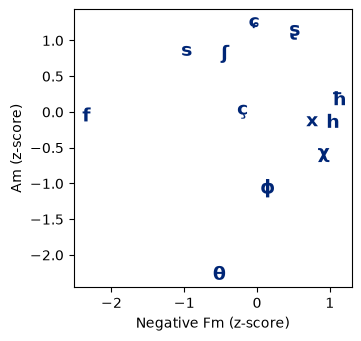

In [43]:
fig, ax = plt.subplots(constrained_layout=True, figsize=(3.5,3.5))
ax.set_box_aspect(1)

ax.scatter(-fricative_scaled['Fm'], fricative_scaled['Am'], s = 0)
for label, x, y in zip(fricative_scaled['fricative'], -fricative_scaled['Fm'], fricative_scaled['Am']):
    ax.annotate(label, (x, y), ha="center", va="center", fontsize=14, color='#002676', fontweight="bold")
    # ax.set_title(f"Major peak space")
    ax.set_xlabel(f"Negative Fm (z-score)")
    ax.set_ylabel(f"Am (z-score)")

if SAVE_FIGURE_MODE:
    fig.savefig(FIGURE_DIR / 'icphs_peak_space.png', bbox_inches="tight")
plt.show()